# [Lab Session 3](fourier.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


(512, 512)
(256, 256)


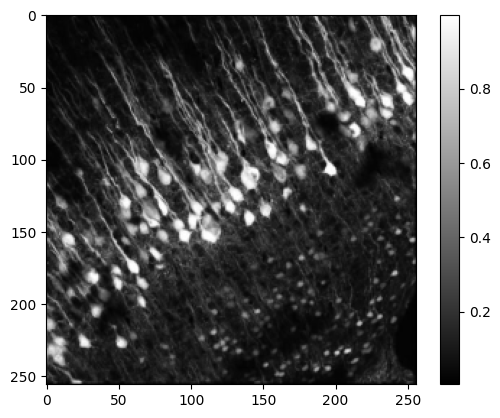

In [ ]:
cell_img = plt.imread('data/cells.png')
print(cell_img.shape)                   #Ursprüngliche Größe

cell_img_resized = resize(cell_img, (256,256))
print(cell_img_resized.shape)

plt.imshow(cell_img_resized, 'grey')
plt.colorbar ()

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [27]:
cell_ft = np.fft.fft2(cell_img_resized)
print(cell_ft.dtype)

complex128


**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [28]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)


<Figure size 640x480 with 0 Axes>

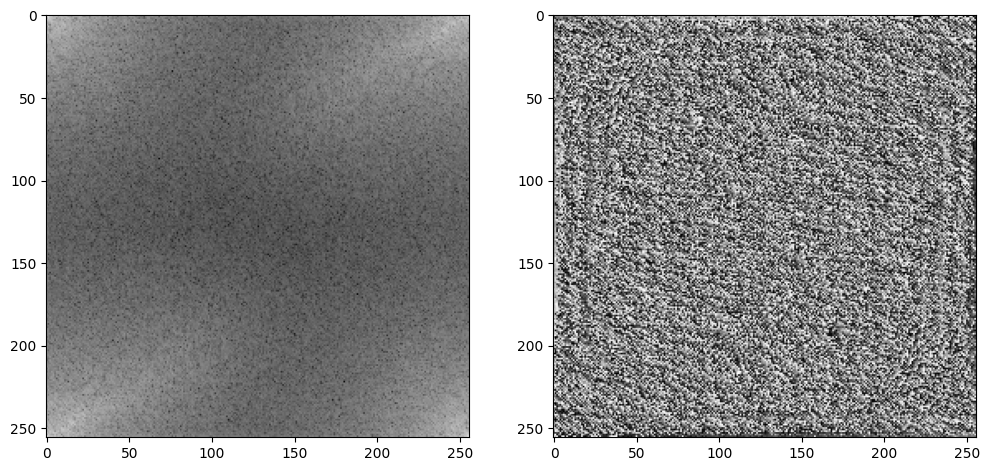

In [29]:
plt.figure()
plt.figure(figsize=(12,6))
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


<Figure size 640x480 with 0 Axes>

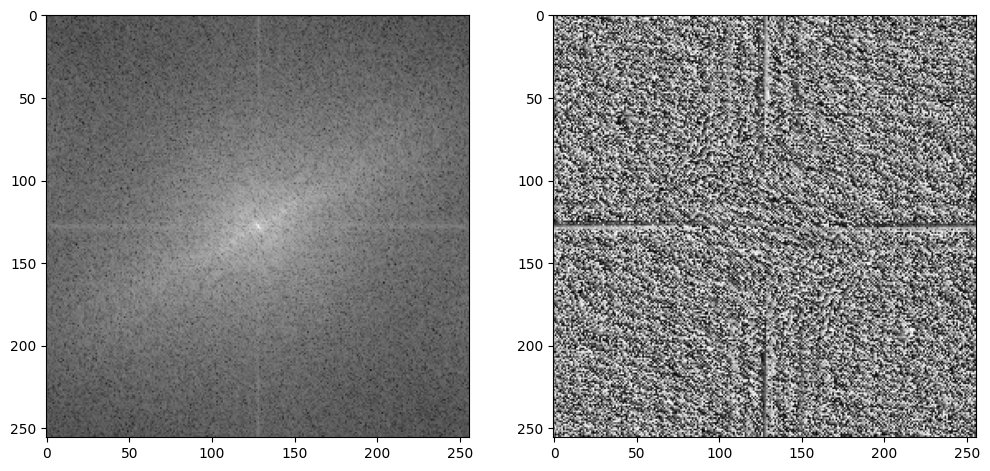

In [53]:
cells_amplitude_shifted = np.abs(np.fft.fftshift(cell_ft))
cells_phase_shifted = np.angle(np.fft.fftshift(cell_ft))

plt.figure()
plt.figure(figsize=(12,6))
plt.subplot(1, 2, 1)
plt.imshow(np.log(cells_amplitude_shifted), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(cells_phase_shifted, 'gray')

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


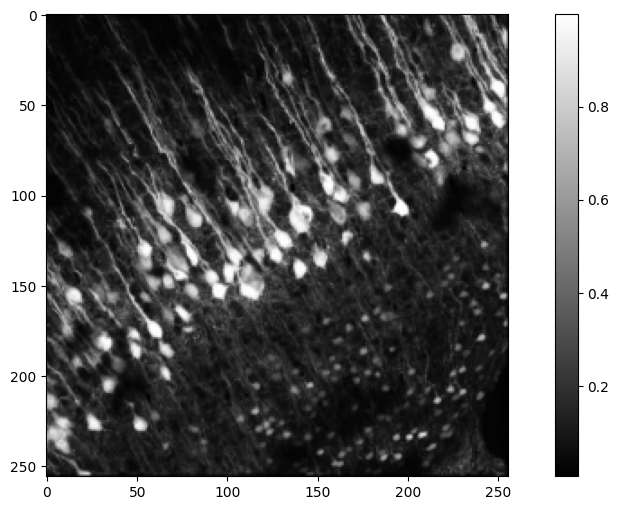

In [36]:
cell_restored = np.fft.ifft2(cell_ft).real

plt.figure(figsize=(12,6))
plt.imshow(cell_restored, 'grey')
plt.colorbar ()


---


**[Task 2 (a).]()** Load the brain MR image.


(256, 256)


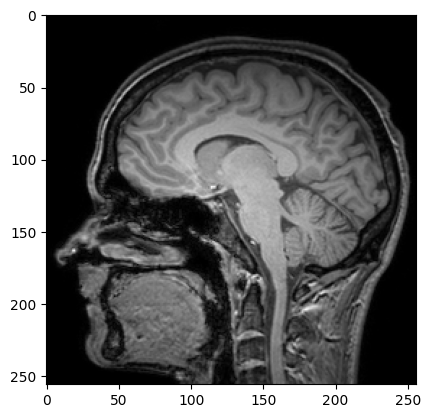

In [61]:
brain_img = plt.imread('data/brain_mri.png')
plt.imshow(brain_img, 'grey')

print(brain_img.shape)


**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


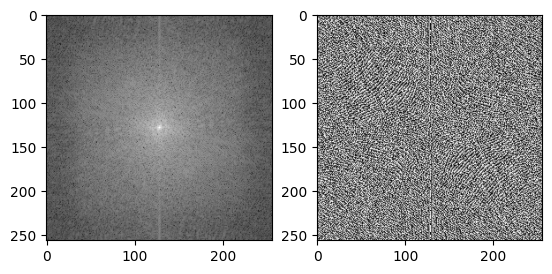

In [50]:
brain_img_ft = np.fft.fftshift(np.fft.fft2(brain_img))
brain_amplitude_shifted = np.abs(brain_img_ft)
brain_phase_shifted = np.angle(brain_img_ft)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(brain_amplitude_shifted), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(brain_phase_shifted, 'gray')

In [55]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


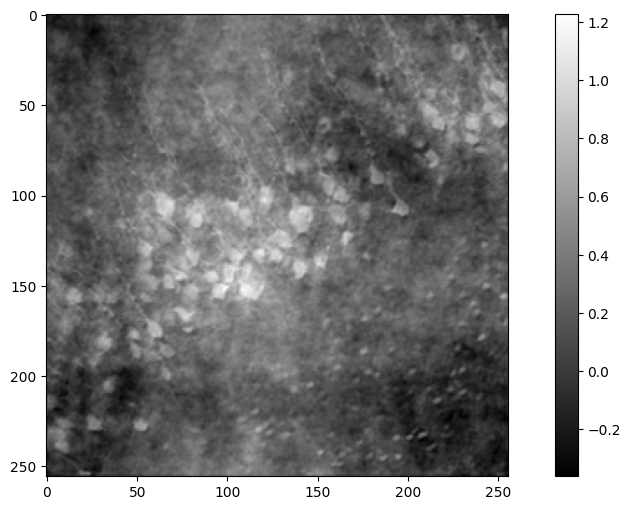

In [ ]:
brain_ft = np.fft.fft2(brain_img)            # ohne Shift
cell_ft  = np.fft.fft2(cell_img_resized)     # ohne Shift

merge_brain_cells = to_complex_array(np.abs(brain_ft), np.angle(cell_ft))

merge1_restored = np.fft.ifft2(merge_brain_cells).real

plt.figure(figsize=(12, 6))
plt.imshow(merge1_restored, cmap='gray')
plt.colorbar()


**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


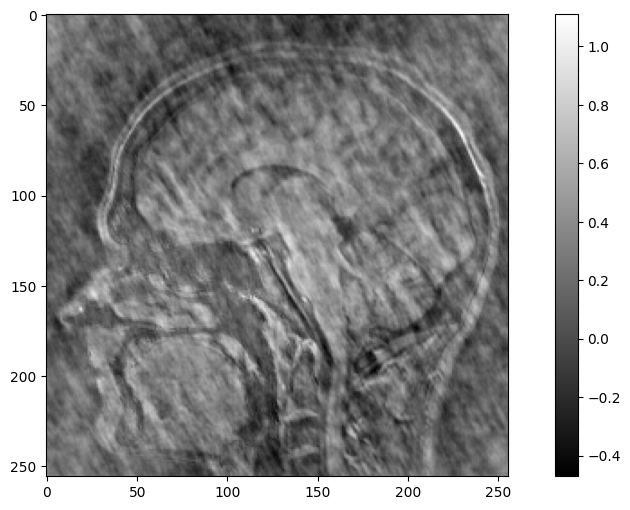

In [ ]:
brain_ft = np.fft.fft2(brain_img)            # ohne Shift
cell_ft  = np.fft.fft2(cell_img_resized)     # ohne Shift

merge_brain_cells = to_complex_array(np.abs(cell_ft), np.angle(brain_ft))

merge1_restored = np.fft.ifft2(merge_brain_cells).real

plt.figure(figsize=(12, 6))
plt.imshow(merge1_restored, cmap='gray')
plt.colorbar()


# --> Phase beinhaltet mehr Information

---


**[Task 3 (a).]()** Create a lowpass filter mask.


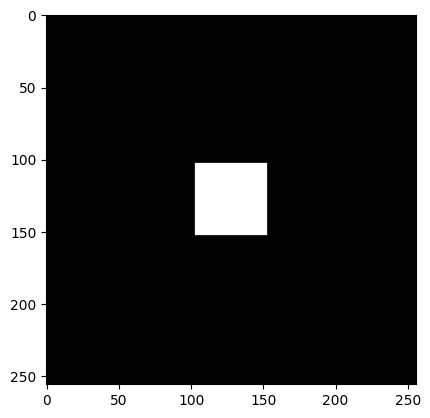

In [66]:
filter_window_size = 50
mask = np.zeros((256,256))                     # 256 x 256 Array nur mit 0en
mask[128-25:128+25, 128-25:128+25]=1                           # filter mit 1en in der mitte mit window_size einfügen

plt.imshow(mask,'grey')

**[Task 3 (b).]()** Create a highpass filter maks.


**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


Due to high computational costs, we need to resize the image.


In [ ]:
test_img = resize(brain_img, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


**[Task 4 (f).]()** Round the arrays and compare them again.


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)
